# Exploratory Data Analysis: Mall Customers

This notebook performs an exploratory data analysis of the Mall Customers dataset.

The analysis covers:

1. Data loading and inspection
2. Data cleaning checks
3. Descriptive statistics
4. Histograms
5. Box plots
6. Scatter plots
7. Correlation analysis and heatmap
8. Pair plot
9. Categorical analysis
10. Findings and conclusion

The dataset contains customer demographic information and spending data. The numerical variables used for the main analysis are Age, Annual Income, and Spending Score.

## 1. Import Libraries

The libraries below are used for data handling, numerical analysis, and visualization.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

## 2. Load the Dataset

The dataset is stored as an Excel file. Keep `Mall Customers.xlsx` in the same folder as this notebook.

In [2]:
file_path = "Mall Customers.xlsx"
df = pd.read_excel(file_path)

print("Dataset loaded successfully.")
print(f"Rows: {df.shape[0]}")
print(f"Columns: {df.shape[1]}")

Dataset loaded successfully.
Rows: 200
Columns: 7


## 3. Initial Data Inspection

The first few rows, column names, data types, and basic dataset size are checked before starting the analysis.

In [3]:
print("First 5 rows:")
display(df.head())

print("Dataset shape:")
print(df.shape)

print("Column names:")
print(df.columns.tolist())

print("Data types:")
display(df.dtypes)

First 5 rows:


,CustomerID,Gender,Age,Education,Marital Status,Annual Income (k$),Spending Score (1-100)
0,1,M,19,High School,Married,15,39
1,2,M,21,Graduate,Single,15,81
2,3,F,20,Graduate,Married,16,6
3,4,F,23,High School,Unknown,16,77
4,5,F,31,Uneducated,Married,17,40


Dataset shape:
(200, 7)
Column names:
['CustomerID', 'Gender', 'Age', 'Education ', 'Marital Status', 'Annual Income (k$)', 'Spending Score (1-100)']
Data types:


CustomerID                 int64
Gender                    object
Age                        int64
Education                 object
Marital Status            object
Annual Income (k$)         int64
Spending Score (1-100)     int64
dtype: object

## 4. Data Cleaning Checks

The column names are cleaned by removing extra spaces. Then missing values and duplicate rows are checked. No rows are removed automatically because the checks are performed before making any changes to the data.

In [4]:
# Remove accidental spaces from column names
df.columns = df.columns.str.strip()

print("Missing values:")
display(df.isnull().sum())

print("Total missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

print("Unique values in categorical columns:")
for column in df.select_dtypes(include="object").columns:
    print(f"\n{column}:")
    print(df[column].value_counts())

Missing values:


CustomerID                0
Gender                    0
Age                       0
Education                 0
Marital Status            0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

Total missing values: 0
Duplicate rows: 0
Unique values in categorical columns:

Gender:
Gender
F    112
M     88
Name: count, dtype: int64

Education:
Education
Graduate         67
High School      40
Uneducated       31
Unknown          26
College          17
Doctorate        11
Post-Graduate     8
Name: count, dtype: int64

Marital Status:
Marital Status
Married     112
Single       61
Unknown      15
Divorced     12
Name: count, dtype: int64


## 5. Descriptive Statistics

Descriptive statistics show the count, mean, standard deviation, minimum, quartiles, and maximum for numerical variables.

In [5]:
numeric_cols = [
    "Age",
    "Annual Income (k$)",
    "Spending Score (1-100)"
]

display(df[numeric_cols].describe().round(2))

,Age,Annual Income (k$),Spending Score (1-100)
count,200.00,200.00,200.00
mean,38.85,60.56,50.20
std,13.97,26.26,25.82
min,18.00,15.00,1.00
25%,28.75,41.50,34.75
50%,36.00,61.50,50.00
75%,49.00,78.00,73.00
max,70.00,137.00,99.00


### Summary of the Numerical Variables

The dataset has 200 customers. The average age is 38.85 years. The average annual income is 60.56 k$, and the average spending score is 50.20.

Age ranges from 18 to 70 years. Annual income ranges from 15 k$ to 137 k$. Spending scores range from 1 to 99.

## 6. Histograms

Histograms show the distribution of the numerical variables. They help identify concentration, spread, skewness, and possible multiple groups.

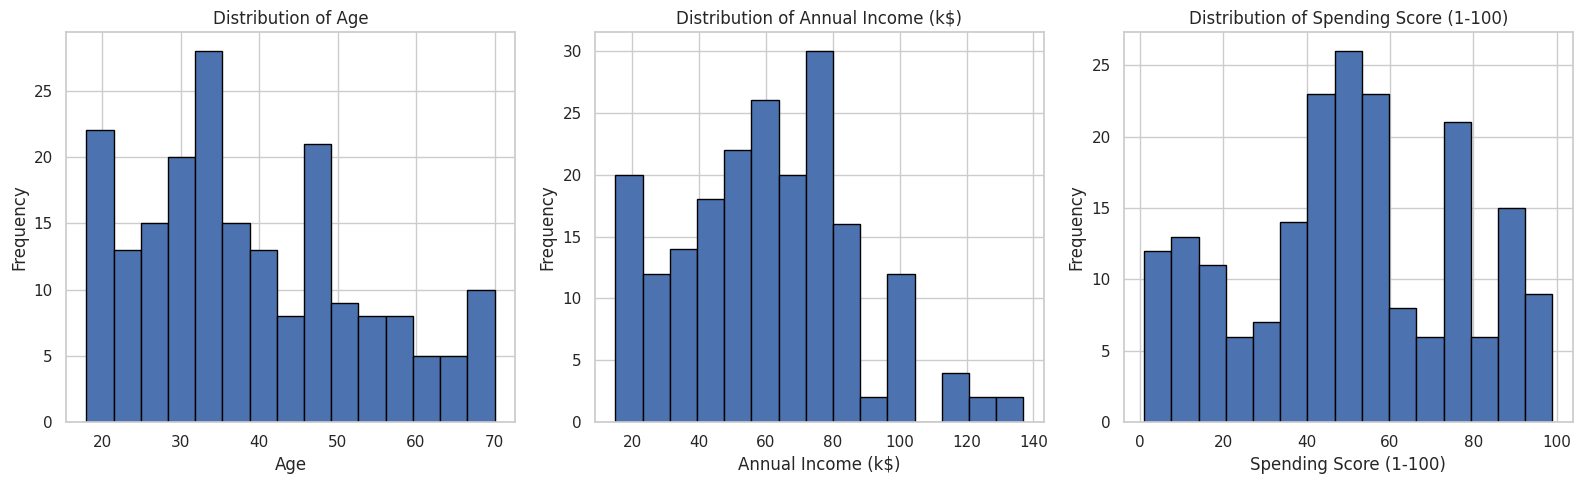

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, column in zip(axes, numeric_cols):
    ax.hist(df[column], bins=15, edgecolor="black")
    ax.set_title(f"Distribution of {column}")
    ax.set_xlabel(column)
    ax.set_ylabel("Frequency")

plt.tight_layout()
plt.show()


## 7. Box Plots

Box plots show the median, quartiles, spread, and possible outliers for each numerical variable.

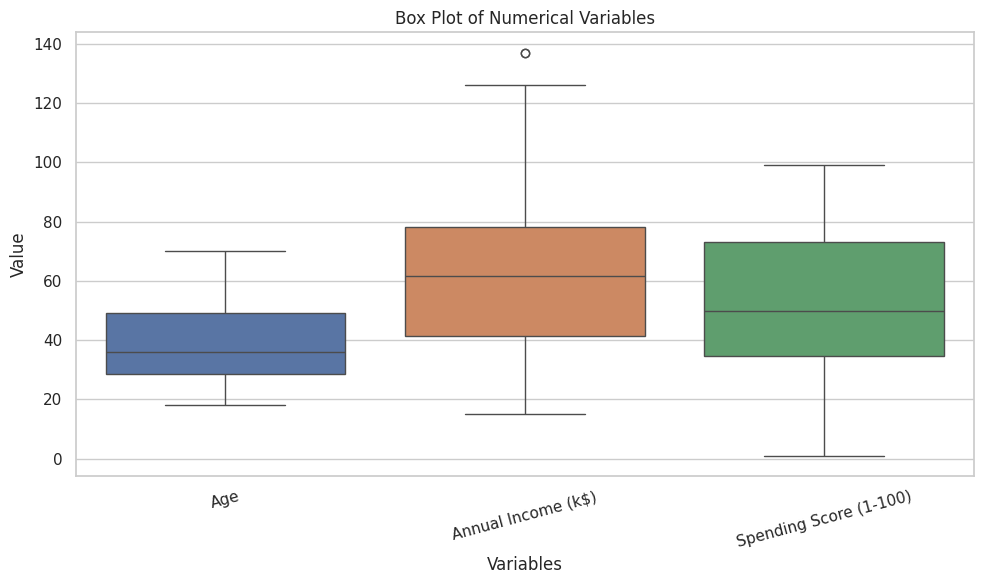

In [7]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=df[numeric_cols])
plt.title("Box Plot of Numerical Variables")
plt.xlabel("Variables")
plt.ylabel("Value")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

## 8. Scatter Plots

Scatter plots are used to examine relationships between pairs of numerical variables.

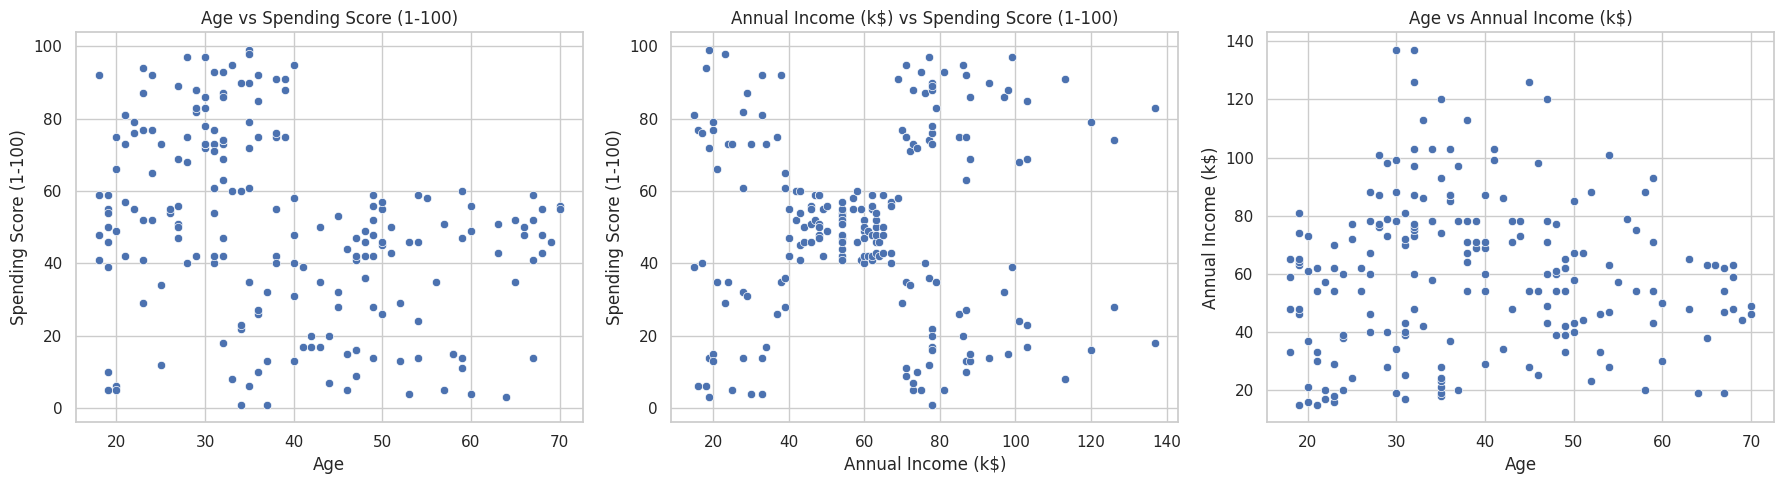

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

plot_pairs = [
    ("Age", "Spending Score (1-100)"),
    ("Annual Income (k$)", "Spending Score (1-100)"),
    ("Age", "Annual Income (k$)")
]

for ax, (x, y) in zip(axes, plot_pairs):
    sns.scatterplot(data=df, x=x, y=y, ax=ax)
    ax.set_title(f"{x} vs {y}")

plt.tight_layout()
plt.show()

### Scatter Plot Observations

The relationship between age and spending score is not strongly linear. Customers of different ages can have both low and high spending scores.

Annual income and spending score also do not show a strong overall linear relationship. The plot suggests that customers with similar incomes can have very different spending scores.

The age and annual income plot shows some variation across age groups rather than a clear straight-line relationship.

## 9. Correlation Analysis

Correlation measures the strength and direction of a linear relationship between numerical variables. Values close to 1 indicate a strong positive relationship, values close to -1 indicate a strong negative relationship, and values close to 0 indicate a weak linear relationship.

In [9]:
correlation = df[numeric_cols].corr()
display(correlation.round(2))

,Age,Annual Income (k$),Spending Score (1-100)
Age,1.00,-0.01,-0.33
Annual Income (k$),-0.01,1.00,0.01
Spending Score (1-100),-0.33,0.01,1.00


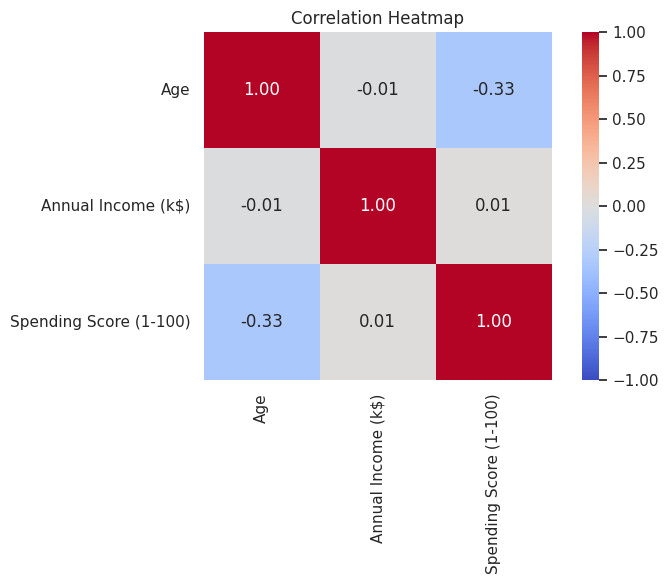

In [10]:
plt.figure(figsize=(8, 6))
sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    square=True
)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

### Correlation Interpretation

The correlation values show that the numerical variables do not have strong overall linear relationships. This is consistent with the scatter plots.

Correlation only measures linear association. A weak correlation does not mean that two variables have no useful relationship.

## 10. Pair Plot

A pair plot combines scatter plots and distributions for all selected numerical variables. It gives an overall view of their relationships.

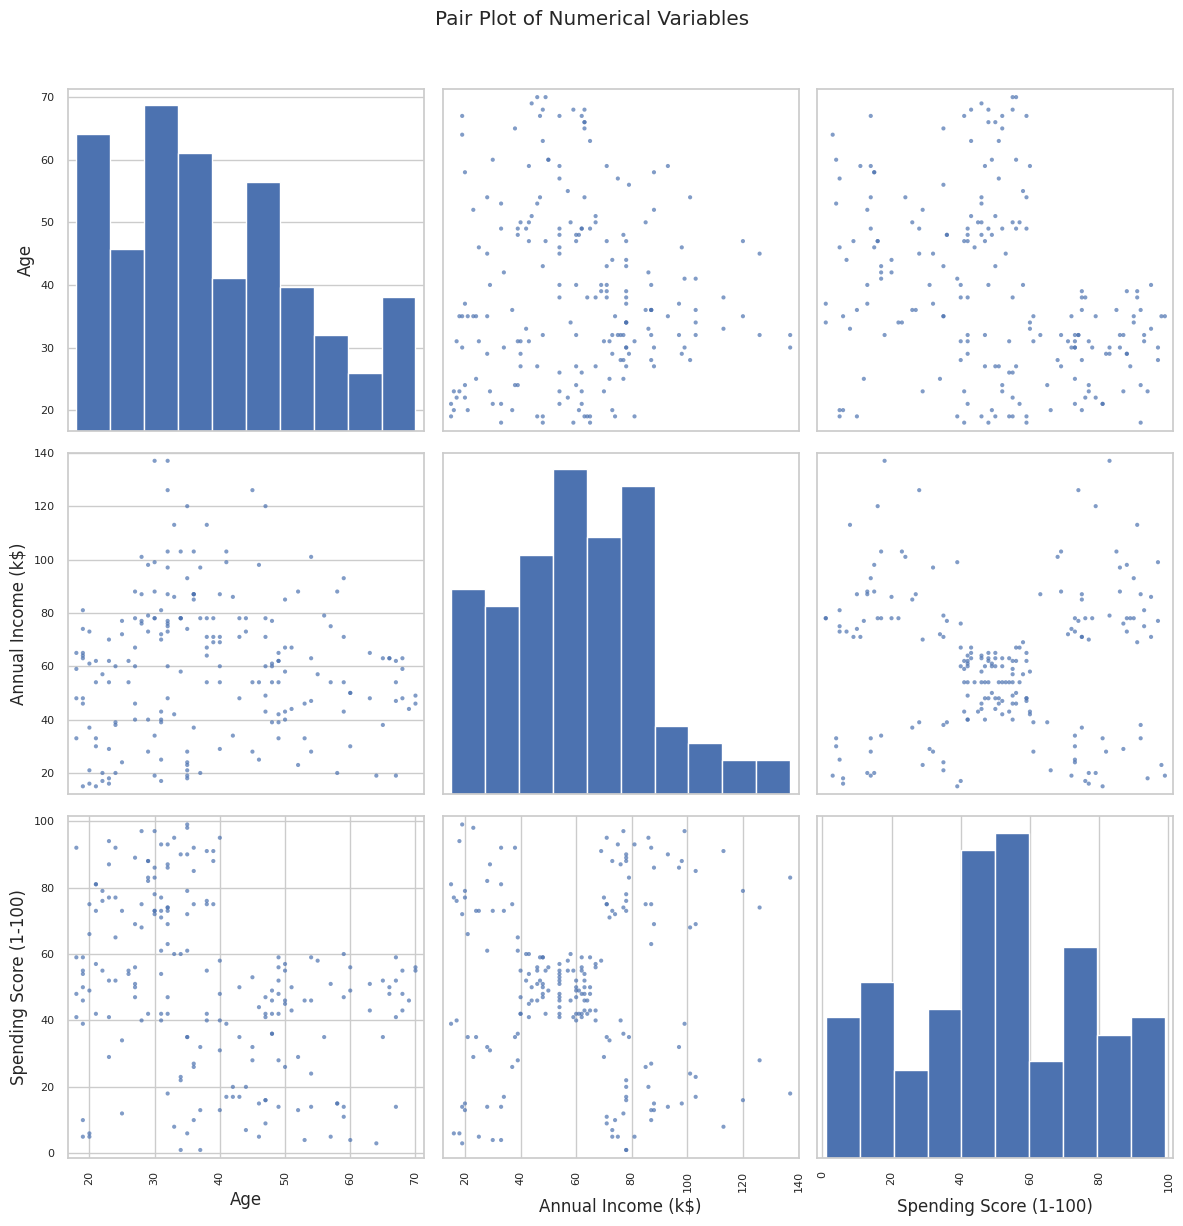

In [11]:
from pandas.plotting import scatter_matrix

scatter_matrix(df[numeric_cols], figsize=(12, 12), diagonal="hist", alpha=0.7)
plt.suptitle("Pair Plot of Numerical Variables", y=1.02)
plt.tight_layout()
plt.show()


## 11. Categorical Analysis

Gender, Education, and Marital Status are categorical variables. Their frequencies are examined below.

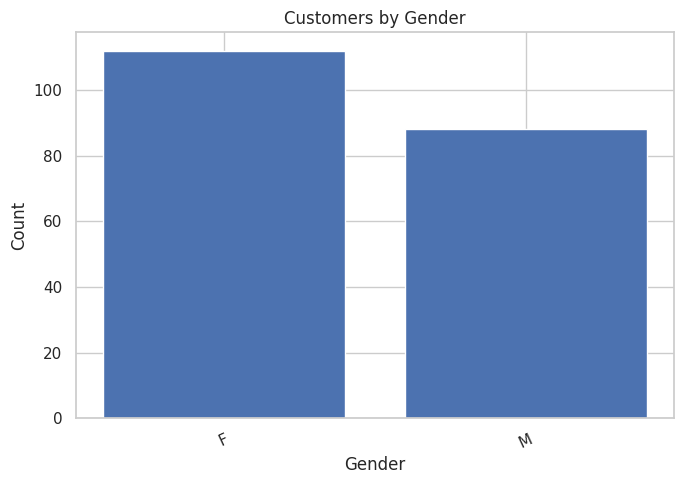

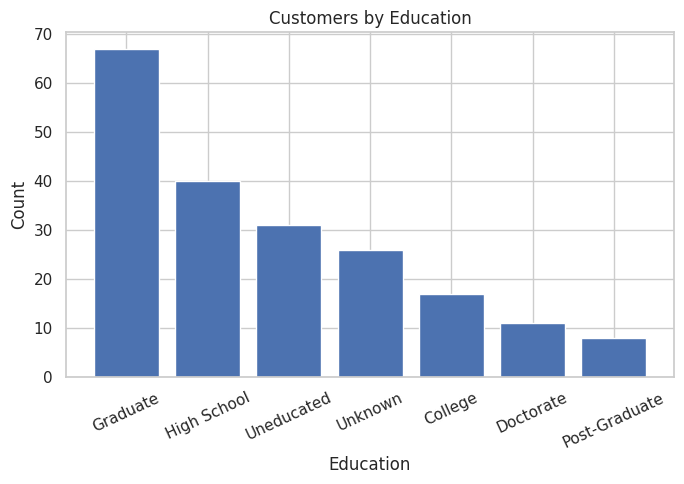

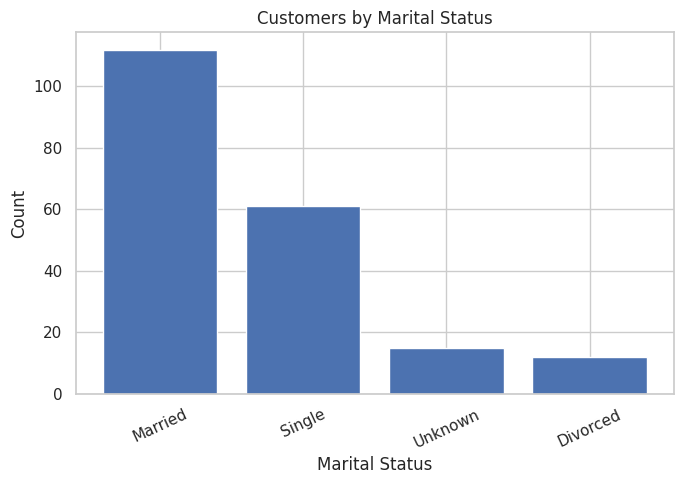

In [12]:
categorical_cols = ["Gender", "Education", "Marital Status"]

# Use a standard bar chart for compatibility across plotting environments
for column in categorical_cols:
    counts = df[column].value_counts()
    plt.figure(figsize=(7, 5))
    plt.bar(counts.index.astype(str), counts.values)
    plt.title(f"Customers by {column}")
    plt.xlabel(column)
    plt.ylabel("Count")
    plt.xticks(rotation=25)
    plt.tight_layout()
    plt.show()


### Spending Score by Gender

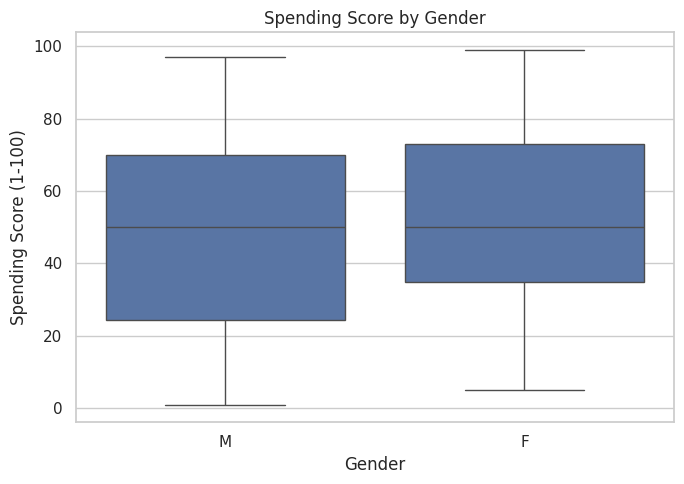

In [13]:
plt.figure(figsize=(7, 5))
sns.boxplot(data=df, x="Gender", y="Spending Score (1-100)")
plt.title("Spending Score by Gender")
plt.xlabel("Gender")
plt.ylabel("Spending Score (1-100)")
plt.tight_layout()
plt.show()

## 12. Key Findings

The main findings from the EDA are:

- The dataset contains 200 customer records and 7 columns.
- There are no missing values in the dataset.
- There are no duplicate rows.
- The dataset contains both numerical and categorical variables, which makes it suitable for several EDA techniques.
- The average customer age is 38.85 years.
- The average annual income is 60.56 k$.
- The average spending score is 50.20.
- Spending score varies widely across customers.
- The scatter plots do not show strong overall linear relationships among age, annual income, and spending score.
- The correlation heatmap supports the observation that the numerical variables have weak overall linear correlations.
- The categorical plots show differences in the number of customers across gender, education, and marital status categories.

## 13. Conclusion

The Mall Customers dataset provides useful demographic and spending information for exploratory data analysis. Descriptive statistics summarize the main numerical variables, while histograms show their distributions and box plots show their spread and possible outliers.

Scatter plots and the correlation heatmap show that age, annual income, and spending score do not have strong overall linear relationships. The pair plot gives a broader view of these relationships. Categorical analysis adds information about gender, education, and marital status.

Overall, the analysis shows why both numerical and categorical visualizations are useful when exploring customer data.